In [1]:
import kagglehub

# Download the latest dataset version
path = kagglehub.dataset_download("nehalbirla/vehicle-dataset-from-cardekho")

print("Path to dataset files:", path)

100%|██████████| 292k/292k [00:00<00:00, 486kB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/nehalbirla/vehicle-dataset-from-cardekho/versions/4


In [2]:
import os
import pandas as pd

# Locate and load the CSV file
file_path = os.path.join(path, "car data.csv")
df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Dataset shape: (301, 9)


,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


In [3]:
# Display the first five rows
df.head()
# Display dataset information
df.info()
# Display column names
print(df.columns.tolist())
# Display dataset dimensions
print("Dataset Shape:", df.shape)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    object 
 1   Year           301 non-null    int64  
 2   Selling_Price  301 non-null    float64
 3   Present_Price  301 non-null    float64
 4   Kms_Driven     301 non-null    int64  
 5   Fuel_Type      301 non-null    object 
 6   Seller_Type    301 non-null    object 
 7   Transmission   301 non-null    object 
 8   Owner          301 non-null    int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 21.3+ KB
['Car_Name', 'Year', 'Selling_Price', 'Present_Price', 'Kms_Driven', 'Fuel_Type', 'Seller_Type', 'Transmission', 'Owner']
Dataset Shape: (301, 9)


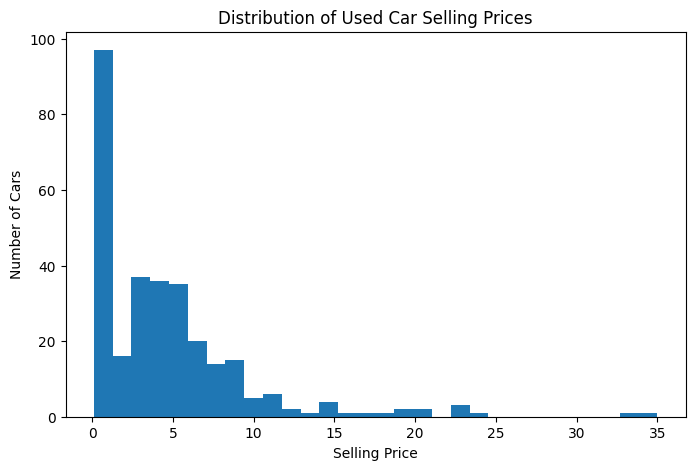

In [4]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.hist(df['Selling_Price'], bins=30)
plt.xlabel("Selling Price")
plt.ylabel("Number of Cars")
plt.title("Distribution of Used Car Selling Prices")
plt.show()


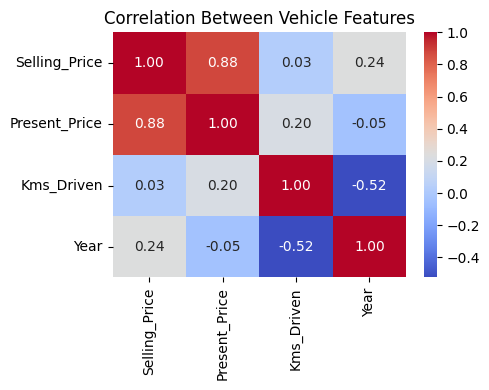

In [5]:
import seaborn as sns
import matplotlib.pyplot as plt

correlation = df[['Selling_Price', 'Present_Price', 'Kms_Driven', 'Year']].corr()

plt.figure(figsize=(5, 4))
sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)
plt.title("Correlation Between Vehicle Features")
plt.tight_layout()
plt.show()


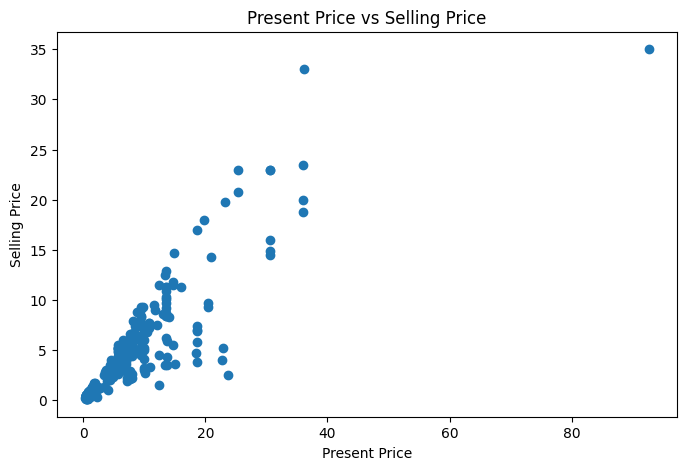

In [6]:
plt.figure(figsize=(8, 5))

plt.scatter(df['Present_Price'], df['Selling_Price'])

plt.xlabel("Present Price")
plt.ylabel("Selling Price")
plt.title("Present Price vs Selling Price")

plt.show()


In [7]:
# Select input features
X = df[['Present_Price', 'Kms_Driven', 'Year']]

# Select target variable
y = df['Selling_Price']

print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())


Features:
   Present_Price  Kms_Driven  Year
0           5.59       27000  2014
1           9.54       43000  2013
2           9.85        6900  2017
3           4.15        5200  2011
4           6.87       42450  2014

Target:
0    3.35
1    4.75
2    7.25
3    2.85
4    4.60
Name: Selling_Price, dtype: float64


In [8]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)


Training data: (240, 3)
Testing data: (61, 3)


In [10]:
from sklearn.linear_model import LinearRegression

# Create the Linear Regression model
model = LinearRegression()


In [11]:
# Train the model using the training data
model.fit(X_train, y_train)

print("Model trained successfully.")
# Display model parameters
print("Intercept:", model.intercept_)
print("Coefficients:", model.coef_)


Model trained successfully.
Intercept: -893.195932878583
Coefficients: [ 5.15430469e-01 -7.45847218e-07  4.43962472e-01]


In [12]:
# Predict selling prices for the test data
y_pred = model.predict(X_test)

print("Predicted Selling Prices:")
print(y_pred[:10])


Predicted Selling Prices:
[ 2.10830482  8.83407476  4.85685547 -0.11971186 10.06284876  5.95448779
  2.12673808  1.39209688  2.10030038  6.03945488]


In [13]:
import pandas as pd

prediction_results = pd.DataFrame({
    'Actual Selling Price': y_test.values,
    'Predicted Selling Price': y_pred
})

prediction_results['Difference'] = (
    prediction_results['Actual Selling Price'] -
    prediction_results['Predicted Selling Price']
)

print("Actual vs Predicted Prices:")
print(prediction_results.head(10))


Actual vs Predicted Prices:
   Actual Selling Price  Predicted Selling Price  Difference
0                  0.35                 2.108305   -1.758305
1                 10.11                 8.834075    1.275925
2                  4.95                 4.856855    0.093145
3                  0.15                -0.119712    0.269712
4                  6.95                10.062849   -3.112849
5                  7.45                 5.954488    1.495512
6                  1.10                 2.126738   -1.026738
7                  0.50                 1.392097   -0.892097
8                  0.45                 2.100300   -1.650300
9                  6.00                 6.039455   -0.039455


In [14]:
from sklearn.metrics import mean_absolute_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Model Performance")
print("------------------")
print(f"Mean Absolute Error: {mae:.2f}")
print(f"R² Score: {r2:.2f}")


Model Performance
------------------
Mean Absolute Error: 1.36
R² Score: 0.83


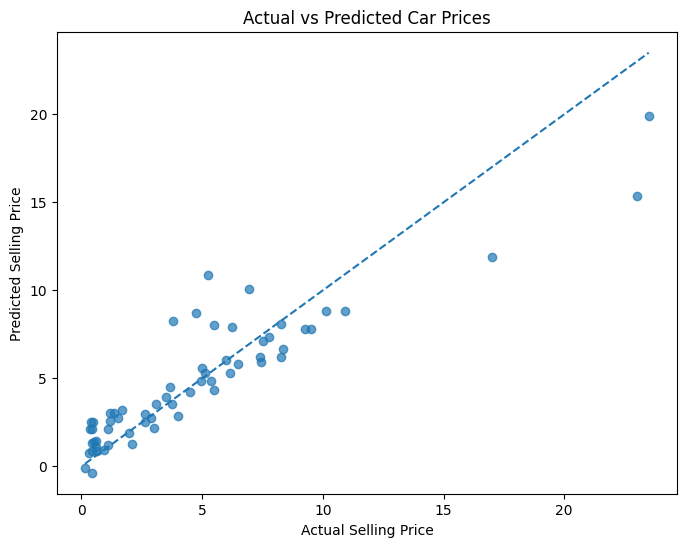

In [15]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.7)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle='--'
)

plt.xlabel("Actual Selling Price")
plt.ylabel("Predicted Selling Price")
plt.title("Actual vs Predicted Car Prices")

plt.show()


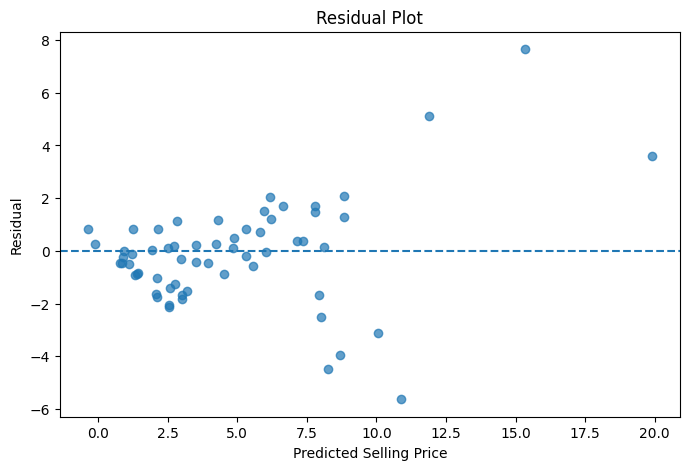

In [16]:
residuals = y_test - y_pred

plt.figure(figsize=(8, 5))

plt.scatter(y_pred, residuals, alpha=0.7)
plt.axhline(y=0, linestyle='--')

plt.xlabel("Predicted Selling Price")
plt.ylabel("Residual")
plt.title("Residual Plot")

plt.show()


In [17]:
new_car = pd.DataFrame({
    'Present_Price': [8.5],
    'Kms_Driven': [30000],
    'Year': [2018]
})

prediction = model.predict(new_car)

print(f"Estimated Selling Price: {prediction[0]:.2f} lakhs")


Estimated Selling Price: 7.08 lakhs
